# Pulso Fase 4 - Notebook 1: Pré-processamento e organização das imagens

Autor: Richard Schmitz | RM 567951 | Turma 2TIAOR-2026
Projeto: Pulso, Inteligência Cardiológica com Consciência de Dados (CardioIA, FIAP)

## Objetivo

Preparar radiografias de tórax para treinar redes neurais convolucionais (CNN) que detectam **cardiomegalia** (aumento da silhueta cardíaca). Este notebook cobre a Parte 1 do enunciado: seleção do dataset, pré-processamento (redimensionamento, normalização, conversão de formato), criação dos conjuntos de treino, validação e teste, e documentação do pipeline.

## Dataset

NIH Chest X-rays, versão amostra (Kaggle: `nih-chest-xrays/sample`), sugerida no enunciado. Os rótulos de cada imagem foram extraídos dos laudos radiológicos que a acompanham.

## Decisões do pipeline e justificativas

| Decisão | Escolha | Por quê |
|---|---|---|
| Tarefa | Classificação binária: cardiomegalia (1) contra sem achados (0) | Mantém o foco cardiovascular do projeto e permite métricas simples de interpretar |
| Imagens com outras doenças e sem cardiomegalia | Excluídas | Evitam um rótulo 0 ambíguo. Limitação: o modelo não é testado contra outras doenças |
| Divisão dos dados | **Por paciente**, estratificada pelo rótulo, cerca de 70% / 15% / 15% | O mesmo paciente tem várias imagens. Dividir por imagem colocaria o mesmo paciente em treino e teste e inflaria as métricas |
| Cor | Escala de cinza (1 canal) | Radiografia é monocromática. Cada canal extra seria redundante |
| Tamanho | 224 x 224 | Entrada padrão de VGG16 e ResNet, usadas no Transfer Learning |
| Normalização | Valores de 0 a 255 para 0 a 1, aplicada na hora do treino | Mantém o arquivo em uint8 (menor) e deixa a normalização específica de cada modelo para o Notebook 2 |
| Formato salvo | Arrays uint8 em `.npz` | Carregamento rápido sem decodificar PNG a cada época |
| Aumento de dados | Sem espelhamento horizontal | Espelhar troca o lado do coração e cria um padrão que não existe na prática |
| Semente | 42 | Reprodutibilidade |

## Aviso

Projeto acadêmico. Nada aqui produz diagnóstico nem deve apoiar decisão clínica.

In [1]:
import os
import sys
import json
import shutil
import subprocess
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold
import sklearn

try:
    from IPython.display import display
except ImportError:
    display = print

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(x, **kwargs):
        return x

warnings.filterwarnings("ignore")

SEED = 42        # semente unica do projeto, para reproduzir a divisao dos dados
TAMANHO = 224    # lado da imagem final, em pixels (entrada padrao de VGG16/ResNet)

# Detecta se esta rodando no Google Colab ou localmente
try:
    import google.colab  # noqa: F401
    COLAB = True
except ImportError:
    COLAB = False

print("Ambiente:", "Google Colab" if COLAB else "Local")

Ambiente: Google Colab


## 1. Pastas de trabalho

No Colab, o notebook tenta usar o Google Drive para guardar o dataset. Assim o download (grande) acontece uma vez só e os Notebooks 2 e 3 reaproveitam os arquivos. Se o Drive não for montado, usa o disco temporário do Colab.

In [2]:
BASE = Path("/content/pulso_f4") if COLAB else Path("./pulso_f4")
if COLAB:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        BASE = Path("/content/drive/MyDrive/Pulso_F4")
    except Exception as erro:
        print("Drive nao montado, usando o disco temporario:", erro)

DATA = BASE / "data"      # dataset baixado
SAIDA = BASE / "saida"    # arrays, splits e resumos gerados por este notebook
DATA.mkdir(parents=True, exist_ok=True)
SAIDA.mkdir(parents=True, exist_ok=True)
print("Dados :", DATA)
print("Saida :", SAIDA)

Mounted at /content/drive
Dados : /content/drive/MyDrive/Pulso_F4/data
Saida : /content/drive/MyDrive/Pulso_F4/saida


## 2. Download do dataset (Kaggle)

O download usa a API do Kaggle. Há duas formas de informar as credenciais:

1. **Secrets do Colab** (recomendado): no painel lateral, aba de chaves, crie `KAGGLE_USERNAME` e `KAGGLE_KEY` e ative o acesso ao notebook.
2. **Upload do `kaggle.json`**: se os Secrets não existirem, o notebook pede o arquivo (Kaggle, Settings, API, Create New Token).

Nunca coloque o token no código nem no repositório.

In [3]:
def configurar_kaggle():
    """Configura as credenciais do Kaggle por variaveis de ambiente, Secrets do Colab ou upload do kaggle.json."""
    if os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY"):
        return "variaveis de ambiente"
    if COLAB:
        try:
            from google.colab import userdata
            os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
            os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
            return "Secrets do Colab"
        except Exception:
            pass
        from google.colab import files
        print("Envie o arquivo kaggle.json")
        enviado = files.upload()
        if "kaggle.json" not in enviado:
            raise RuntimeError("kaggle.json nao foi enviado")
        destino = Path.home() / ".kaggle"
        destino.mkdir(exist_ok=True)
        (destino / "kaggle.json").write_bytes(enviado["kaggle.json"])
        os.chmod(destino / "kaggle.json", 0o600)
        return "upload do kaggle.json"
    raise RuntimeError("Credenciais do Kaggle nao encontradas")


def baixar_dataset():
    """Baixa e descompacta a amostra do NIH Chest X-rays, se ainda nao estiver na pasta de dados."""
    if any(DATA.rglob("*.csv")):
        print("Dataset ja presente em", DATA)
        return
    origem = configurar_kaggle()
    print("Credenciais via", origem)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kaggle"], check=True)
    try:
        subprocess.run(
            ["kaggle", "datasets", "download", "-d", "nih-chest-xrays/sample",
             "-p", str(DATA), "--unzip"],
            check=True,
        )
    except subprocess.CalledProcessError:
        print("Falha no download automatico. Alternativa manual:")
        print("1) Baixe o dataset em https://www.kaggle.com/datasets/nih-chest-xrays/sample")
        print("2) Descompacte em", DATA)
        raise


baixar_dataset()

Dataset ja presente em /content/drive/MyDrive/Pulso_F4/data


## 3. Descoberta da estrutura real dos arquivos

Em vez de supor nomes de pastas e colunas, o notebook procura o CSV de rótulos, indexa as imagens e confere as colunas. Se faltar algo essencial, ele para e mostra o que encontrou.

In [4]:
def achar_csv_rotulos(pasta):
    """Procura, dentro da pasta, o CSV que contem a coluna de achados (Finding Labels)."""
    for csv in sorted(pasta.rglob("*.csv")):
        colunas = pd.read_csv(csv, nrows=0).columns
        if any("finding" in c.lower() for c in colunas):
            return csv
    raise FileNotFoundError("Nenhum CSV com coluna de achados em " + str(pasta))


def normalizar_colunas(df):
    """Renomeia as colunas para nomes curtos e confere as obrigatorias (imagem, achados, paciente)."""
    mapa = {}
    for col in df.columns:
        chave = col.strip().lower()
        if chave == "image index":
            mapa[col] = "imagem"
        elif chave == "finding labels":
            mapa[col] = "achados"
        elif chave == "patient id":
            mapa[col] = "paciente"
        elif chave == "patient age":
            mapa[col] = "idade"
        elif chave == "patient gender":
            mapa[col] = "sexo"
        elif chave == "view position":
            mapa[col] = "posicao"
    df = df.rename(columns=mapa)
    faltando = [c for c in ["imagem", "achados", "paciente"] if c not in df.columns]
    if faltando:
        raise KeyError("Colunas obrigatorias ausentes: %s. Colunas encontradas: %s" % (faltando, list(df.columns)))
    return df


def indexar_imagens(pasta):
    """Mapeia nome do arquivo para o caminho completo, para qualquer subpasta."""
    extensoes = {".png", ".jpg", ".jpeg"}
    return {p.name: p for p in pasta.rglob("*") if p.suffix.lower() in extensoes}

In [5]:
csv_rotulos = achar_csv_rotulos(DATA)
bruto = pd.read_csv(csv_rotulos)
print("CSV de rotulos :", csv_rotulos.relative_to(DATA))
print("Linhas         :", len(bruto))
print("Colunas        :", list(bruto.columns))

df = normalizar_colunas(bruto)
TEM_SEXO = "sexo" in df.columns
TEM_IDADE = "idade" in df.columns
print("Metadado de sexo  presente:", TEM_SEXO)
print("Metadado de idade presente:", TEM_IDADE)
if not TEM_SEXO:
    print("ATENCAO: sem a coluna de sexo nao e possivel medir fairness por sexo (Ir Alem 1).")

imagens = indexar_imagens(DATA)
print("Imagens encontradas:", len(imagens))

ausentes = ~df["imagem"].isin(imagens.keys())
print("Registros do CSV sem imagem correspondente:", int(ausentes.sum()))
df = df.loc[~ausentes].reset_index(drop=True)
assert df["imagem"].is_unique, "Ha nomes de imagem repetidos no CSV"

CSV de rotulos : sample/sample_labels.csv
Linhas         : 5606
Colunas        : ['Image Index', 'Finding Labels', 'Follow-up #', 'Patient ID', 'Patient Age', 'Patient Gender', 'View Position', 'OriginalImageWidth', 'OriginalImageHeight', 'OriginalImagePixelSpacing_x', 'OriginalImagePixelSpacing_y']
Metadado de sexo  presente: True
Metadado de idade presente: True
Imagens encontradas: 5606
Registros do CSV sem imagem correspondente: 0


## 4. Rótulo binário e limpeza dos metadados

- **Rótulo 1 (cardiomegalia):** o texto de achados contém `Cardiomegaly`, sozinho ou junto de outros achados.
- **Rótulo 0 (sem achados):** o texto de achados é exatamente `No Finding`.
- Imagens com outras doenças e sem cardiomegalia saem do experimento (decisão documentada acima).
- **Idades inválidas** (negativas ou acima de 100 anos) viram valor ausente. Não são trocadas por um valor "plausível": o dado inválido fica visível como inválido.

In [6]:
IDADE_MAX = 100


def criar_rotulo(df):
    """cardiomegalia=1 se 'Cardiomegaly' esta nos achados; 0 se 'No Finding'. Demais casos sao excluidos."""
    achados = df["achados"].fillna("")
    positivo = achados.str.contains("Cardiomegaly", regex=False)
    negativo = achados.eq("No Finding")
    saida = df.loc[positivo | negativo].copy()
    saida["rotulo"] = positivo.loc[saida.index].astype(int)
    return saida


def limpar_metadados(df):
    """Padroniza sexo (M/F) e marca idades invalidas como ausentes, sem inventar valores."""
    df = df.copy()
    if "idade" in df.columns:
        # O CSV do Kaggle pode trazer a idade como texto com unidade (ex.: "058Y"). Extrai numero e unidade.
        texto = df["idade"].astype(str).str.strip().str.upper()
        numero = pd.to_numeric(texto.str.extract(r"(\d+\.?\d*)")[0], errors="coerce")
        unidade = texto.str.extract(r"([YMWD])\s*$")[0].fillna("Y")
        fator = unidade.map({"Y": 1.0, "M": 1 / 12, "W": 1 / 52, "D": 1 / 365})
        df["idade"] = numero * fator
        invalida = (df["idade"] < 0) | (df["idade"] > IDADE_MAX)
        df["idade_invalida"] = invalida
        df.loc[invalida, "idade"] = np.nan
    if "sexo" in df.columns:
        df["sexo"] = df["sexo"].astype(str).str.strip().str.upper().map({"M": "M", "F": "F"})
    return df

In [7]:
total_csv = len(df)
df = limpar_metadados(df)
df = criar_rotulo(df).reset_index(drop=True)

excluidas_outras_doencas = total_csv - len(df)
n_idade_invalida = int(df["idade_invalida"].sum()) if TEM_IDADE else 0
if TEM_IDADE:
    n_com_idade = int(df["idade"].notna().sum())
    print("Registros com idade valida:", n_com_idade, "de", len(df))
    assert n_com_idade > 0, "Nenhuma idade foi lida: confira o formato da coluna Patient Age"

print("Registros apos conferir imagens :", total_csv)
print("Excluidos (outras doencas)      :", excluidas_outras_doencas)
print("Registros no experimento        :", len(df))
print("Idades invalidas marcadas (apenas entre os registros do experimento):", n_idade_invalida)
print()
print(df["rotulo"].map({0: "sem achados", 1: "cardiomegalia"}).value_counts().to_string())

Registros com idade valida: 3184 de 3185
Registros apos conferir imagens : 5606
Excluidos (outras doencas)      : 2421
Registros no experimento        : 3185
Idades invalidas marcadas (apenas entre os registros do experimento): 1

rotulo
sem achados      3044
cardiomegalia     141


## 5. Análise exploratória

Antes de qualquer treino, três perguntas: quão desbalanceado é o problema, quantas imagens há por paciente e como sexo e idade se distribuem entre as classes. As respostas definem as métricas do Notebook 2 e os limites do Ir Além 1.

Prevalencia de cardiomegalia: 4.4%
Pacientes unicos            : 2762
Imagens por paciente        : media 1.15 | maximo 6

Sexo x rotulo (contagem):


rotulo,0,1,All
sexo,,,
F,1343,73,1416
M,1701,68,1769
All,3044,141,3185


Registros com sexo ausente: 0


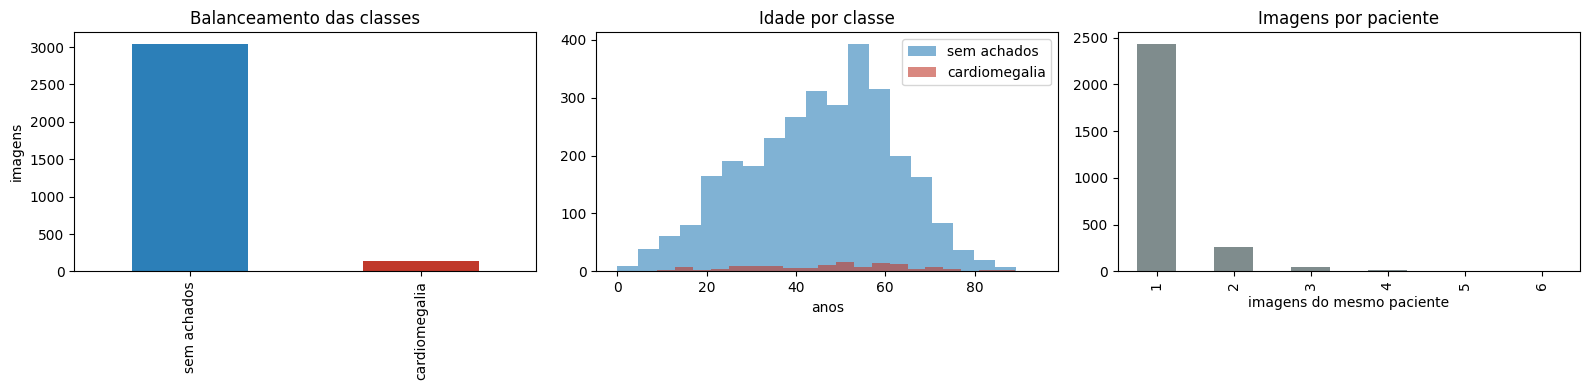

In [8]:
prevalencia = 100 * df["rotulo"].mean()
por_paciente = df.groupby("paciente").size()
print("Prevalencia de cardiomegalia: %.1f%%" % prevalencia)
print("Pacientes unicos            :", df["paciente"].nunique())
print("Imagens por paciente        : media %.2f | maximo %d" % (por_paciente.mean(), por_paciente.max()))

if TEM_SEXO:
    print()
    print("Sexo x rotulo (contagem):")
    display(pd.crosstab(df["sexo"], df["rotulo"], margins=True, dropna=False))
    print("Registros com sexo ausente:", int(df["sexo"].isna().sum()))

fig, eixos = plt.subplots(1, 3, figsize=(16, 4))
df["rotulo"].map({0: "sem achados", 1: "cardiomegalia"}).value_counts().plot(kind="bar", ax=eixos[0], color=["#2c7fb8", "#c0392b"])
eixos[0].set_title("Balanceamento das classes")
eixos[0].set_ylabel("imagens")
eixos[0].set_xlabel("")

if TEM_IDADE:
    for r, nome, cor in [(0, "sem achados", "#2c7fb8"), (1, "cardiomegalia", "#c0392b")]:
        eixos[1].hist(df.loc[df["rotulo"] == r, "idade"].dropna(), bins=20, alpha=0.6, label=nome, color=cor)
    eixos[1].set_title("Idade por classe")
    eixos[1].set_xlabel("anos")
    eixos[1].legend()
else:
    eixos[1].axis("off")

por_paciente.value_counts().sort_index().plot(kind="bar", ax=eixos[2], color="#7f8c8d")
eixos[2].set_title("Imagens por paciente")
eixos[2].set_xlabel("imagens do mesmo paciente")
plt.tight_layout()
plt.savefig(SAIDA / "eda.png", dpi=120)
plt.show()

## 6. Divisão por paciente: treino, validação e teste

`StratifiedGroupKFold` mantém todas as imagens de um paciente na mesma partição e tenta preservar a proporção de cardiomegalia em cada uma. Duas rodadas produzem cerca de 70% / 15% / 15%: a primeira separa 1/7 para teste, a segunda separa 1/6 do restante para validação.

O teste só é usado na avaliação final.

In [9]:
def dividir_por_paciente(df, seed=SEED):
    """Divide em treino/validacao/teste sem repetir paciente entre as particoes (~70/15/15)."""
    indices = np.arange(len(df))
    y = df["rotulo"].values
    grupos = df["paciente"].values

    # Rodada 1: separa ~1/7 (14,3%) para teste
    sgkf_teste = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=seed)
    resto_idx, teste_idx = next(sgkf_teste.split(indices, y, grupos))

    # Rodada 2: do restante, separa ~1/6 (14,3% do total) para validacao
    resto = df.iloc[resto_idx]
    sgkf_val = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=seed)
    treino_rel, val_rel = next(sgkf_val.split(np.arange(len(resto)), resto["rotulo"].values, resto["paciente"].values))

    particao = np.empty(len(df), dtype=object)
    particao[resto_idx[treino_rel]] = "treino"
    particao[resto_idx[val_rel]] = "validacao"
    particao[teste_idx] = "teste"

    saida = df.copy()
    saida["particao"] = particao
    return saida


def verificar_particoes(df):
    """Garante que nenhum paciente aparece em duas particoes e devolve o resumo por particao."""
    pacientes = {nome: set(grupo["paciente"]) for nome, grupo in df.groupby("particao")}
    pares = [("treino", "validacao"), ("treino", "teste"), ("validacao", "teste")]
    for a, b in pares:
        comuns = pacientes[a] & pacientes[b]
        assert not comuns, "Pacientes repetidos entre %s e %s: %d" % (a, b, len(comuns))
    tabela = df.groupby("particao").agg(
        imagens=("rotulo", "size"),
        positivos=("rotulo", "sum"),
        pacientes=("paciente", "nunique"),
    )
    tabela["prevalencia_%"] = (100 * tabela["positivos"] / tabela["imagens"]).round(2)
    return tabela.loc[["treino", "validacao", "teste"]]

In [10]:
df = dividir_por_paciente(df)
tabela_particoes = verificar_particoes(df)
print("Nenhum paciente aparece em mais de uma particao (verificado).")
print()
display(tabela_particoes)

if TEM_SEXO:
    print()
    print("Distribuicao de sexo por particao (contagem de imagens):")
    display(pd.crosstab(df["particao"], df["sexo"], dropna=False).loc[["treino", "validacao", "teste"]])

positivos_teste = int(tabela_particoes.loc["teste", "positivos"])
if positivos_teste < 30:
    print()
    print("ATENCAO: o teste tem apenas %d casos de cardiomegalia." % positivos_teste)
    print("Metricas e comparacoes entre grupos terao incerteza alta e devem ser lidas como hipoteses.")

Nenhum paciente aparece em mais de uma particao (verificado).



,imagens,positivos,pacientes,prevalencia_%
particao,,,,
treino,2277,100,1975,4.39
validacao,462,22,392,4.76
teste,446,19,395,4.26



Distribuicao de sexo por particao (contagem de imagens):


sexo,F,M
particao,,
treino,990,1287
validacao,232,230
teste,194,252



ATENCAO: o teste tem apenas 19 casos de cardiomegalia.
Metricas e comparacoes entre grupos terao incerteza alta e devem ser lidas como hipoteses.


## 7. Pré-processamento das imagens

Para cada imagem: abrir, converter para escala de cinza, redimensionar para 224 x 224 e guardar como `uint8`. A normalização (dividir por 255) acontece no treino, no Notebook 2.

In [11]:
def preprocessar(caminho, tamanho=TAMANHO):
    """Abre a imagem, converte para cinza (1 canal), redimensiona e devolve array uint8 (tamanho x tamanho)."""
    with Image.open(caminho) as imagem:
        imagem = imagem.convert("L")
        imagem = imagem.resize((tamanho, tamanho), Image.Resampling.LANCZOS)
        return np.asarray(imagem, dtype=np.uint8)


def construir_arrays(particao_df):
    """Aplica o pre-processamento a todas as imagens de uma particao."""
    X = np.stack([preprocessar(imagens[nome]) for nome in tqdm(particao_df["imagem"], desc="pre-processando")])
    y = particao_df["rotulo"].values.astype(np.uint8)
    return X, y


def normalizar(X):
    """Normaliza de 0-255 para 0-1 (float32). Usado no treino; os arquivos permanecem em uint8."""
    return X.astype(np.float32) / 255.0

In [12]:
# Tamanho original das imagens (amostra de ate 300 arquivos), para registrar no relatorio
amostra_nomes = list(df["imagem"].iloc[:300])
tamanhos = Counter(Image.open(imagens[n]).size for n in amostra_nomes)
print("Tamanhos originais (largura, altura) na amostra:", dict(tamanhos))

ARQUIVOS = {}
for nome in ["treino", "validacao", "teste"]:
    parte = df.loc[df["particao"] == nome]
    X, y = construir_arrays(parte)
    caminho = SAIDA / ("%s.npz" % nome)
    np.savez_compressed(caminho, X=X, y=y, imagem=parte["imagem"].values.astype(str))
    ARQUIVOS[nome] = caminho
    print("%-10s X=%s dtype=%s | y=%s | positivos=%d" % (nome, X.shape, X.dtype, y.shape, int(y.sum())))

Tamanhos originais (largura, altura) na amostra: {(1024, 1024): 300}


pre-processando:   0%|          | 0/2277 [00:00<?, ?it/s]

treino     X=(2277, 224, 224) dtype=uint8 | y=(2277,) | positivos=100


pre-processando:   0%|          | 0/462 [00:00<?, ?it/s]

validacao  X=(462, 224, 224) dtype=uint8 | y=(462,) | positivos=22


pre-processando:   0%|          | 0/446 [00:00<?, ?it/s]

teste      X=(446, 224, 224) dtype=uint8 | y=(446,) | positivos=19


## 8. Conferência visual

Quatro exemplos de cada classe do conjunto de treino, antes (original) e depois (cinza, 224 x 224). A conferência serve para detectar problemas como imagem cortada, invertida ou em branco.

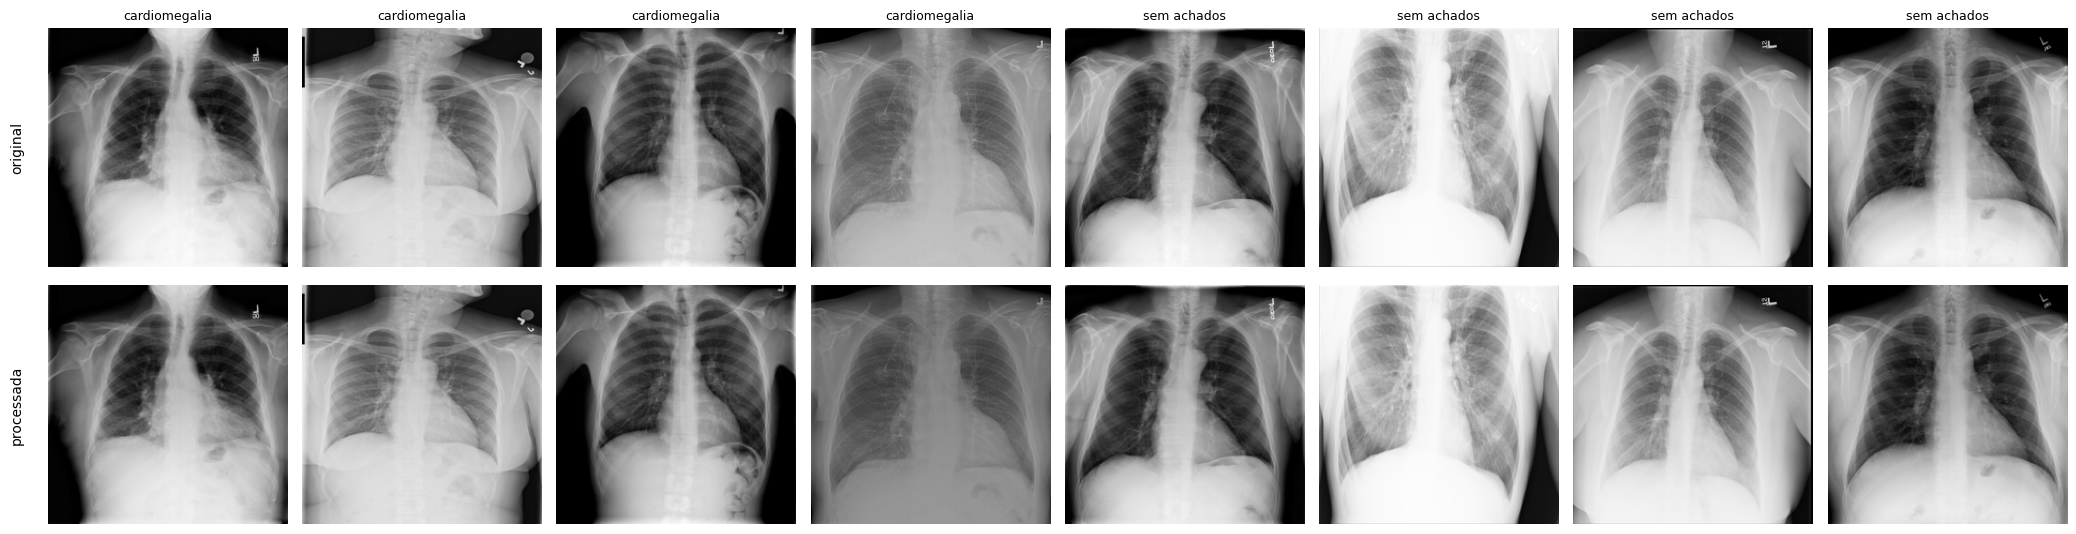

Normalizacao conferida: minimo 0.000 | maximo 1.000 | tipo float32


In [13]:
treino_df = df.loc[df["particao"] == "treino"]
rng = np.random.default_rng(SEED)
escolhidos = []
for rotulo in [1, 0]:
    candidatos = treino_df.loc[treino_df["rotulo"] == rotulo, "imagem"].values
    n = min(4, len(candidatos))
    escolhidos += [(nome, rotulo) for nome in rng.choice(candidatos, size=n, replace=False)]

fig, eixos = plt.subplots(2, len(escolhidos), figsize=(2.6 * len(escolhidos), 5.6))
for i, (nome, rotulo) in enumerate(escolhidos):
    with Image.open(imagens[nome]) as original:
        eixos[0, i].imshow(original.convert("L"), cmap="gray")
    eixos[1, i].imshow(preprocessar(imagens[nome]), cmap="gray", vmin=0, vmax=255)
    eixos[0, i].set_title("cardiomegalia" if rotulo else "sem achados", fontsize=9)
    eixos[0, i].axis("off")
    eixos[1, i].axis("off")
eixos[0, 0].text(-0.1, 0.5, "original", transform=eixos[0, 0].transAxes, rotation=90, va="center", ha="right")
eixos[1, 0].text(-0.1, 0.5, "processada", transform=eixos[1, 0].transAxes, rotation=90, va="center", ha="right")
plt.tight_layout()
plt.savefig(SAIDA / "exemplos_preprocessamento.png", dpi=120)
plt.show()

X_exemplo = normalizar(np.load(ARQUIVOS["treino"])["X"][:64])
print("Normalizacao conferida: minimo %.3f | maximo %.3f | tipo %s" % (X_exemplo.min(), X_exemplo.max(), X_exemplo.dtype))

## 9. Resumo do pipeline e arquivos para o repositório

O resumo abaixo reúne todos os números que o relatório da Parte 1 vai citar. O relatório usa estes valores e nenhum outro. Os arquivos pequenos (`splits.csv`, `pipeline_resumo.json` e as duas figuras) vão para o repositório. Os arrays `.npz` ficam só no Drive.

In [14]:
def resumo_particao(nome):
    parte = df.loc[df["particao"] == nome]
    info = {
        "imagens": int(len(parte)),
        "pacientes": int(parte["paciente"].nunique()),
        "positivos": int(parte["rotulo"].sum()),
        "prevalencia_pct": round(100 * float(parte["rotulo"].mean()), 2),
    }
    if TEM_SEXO:
        info["sexo"] = {str(k): int(v) for k, v in parte["sexo"].value_counts(dropna=False).items()}
    return info


resumo = {
    "dataset": "nih-chest-xrays/sample (Kaggle)",
    "tarefa": "cardiomegalia (1) contra sem achados (0)",
    "semente": SEED,
    "tamanho_imagem": [TAMANHO, TAMANHO],
    "canais": 1,
    "registros_no_csv": int(len(bruto)),
    "excluidos_outras_doencas": int(excluidas_outras_doencas),
    "registros_no_experimento": int(len(df)),
    "idades_invalidas_marcadas_no_experimento": n_idade_invalida,
    "tem_sexo": bool(TEM_SEXO),
    "tem_idade": bool(TEM_IDADE),
    "tamanhos_originais_amostra": {str(k): int(v) for k, v in tamanhos.items()},
    "particoes": {nome: resumo_particao(nome) for nome in ["treino", "validacao", "teste"]},
    "versoes": {
        "python": sys.version.split()[0],
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__,
        "pillow": Image.__version__ if hasattr(Image, "__version__") else "n/d",
    },
}

colunas_split = [c for c in ["imagem", "paciente", "sexo", "idade", "rotulo", "particao"] if c in df.columns]
df[colunas_split].to_csv(SAIDA / "splits.csv", index=False)
(SAIDA / "pipeline_resumo.json").write_text(json.dumps(resumo, indent=2, ensure_ascii=False), encoding="utf-8")

print(json.dumps(resumo, indent=2, ensure_ascii=False))

{
  "dataset": "nih-chest-xrays/sample (Kaggle)",
  "tarefa": "cardiomegalia (1) contra sem achados (0)",
  "semente": 42,
  "tamanho_imagem": [
    224,
    224
  ],
  "canais": 1,
  "registros_no_csv": 5606,
  "excluidos_outras_doencas": 2421,
  "registros_no_experimento": 3185,
  "idades_invalidas_marcadas_no_experimento": 1,
  "tem_sexo": true,
  "tem_idade": true,
  "tamanhos_originais_amostra": {
    "(1024, 1024)": 300
  },
  "particoes": {
    "treino": {
      "imagens": 2277,
      "pacientes": 1975,
      "positivos": 100,
      "prevalencia_pct": 4.39,
      "sexo": {
        "M": 1287,
        "F": 990
      }
    },
    "validacao": {
      "imagens": 462,
      "pacientes": 392,
      "positivos": 22,
      "prevalencia_pct": 4.76,
      "sexo": {
        "F": 232,
        "M": 230
      }
    },
    "teste": {
      "imagens": 446,
      "pacientes": 395,
      "positivos": 19,
      "prevalencia_pct": 4.26,
      "sexo": {
        "M": 252,
        "F": 194
      }
   

In [15]:
# Reune os arquivos pequenos e baixa em um unico zip (Colab). Localmente, apenas informa a pasta.
pacote = SAIDA / "para_repositorio"
pacote.mkdir(exist_ok=True)
for nome in ["splits.csv", "pipeline_resumo.json", "eda.png", "exemplos_preprocessamento.png"]:
    shutil.copy(SAIDA / nome, pacote / nome)

if COLAB:
    from google.colab import files
    zip_path = shutil.make_archive("/content/pulso_f4_nb1_saidas", "zip", pacote)
    files.download(zip_path)
else:
    print("Arquivos para o repositorio em:", pacote)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Limitações deste pipeline

- Os rótulos vêm dos laudos que acompanham as imagens. São referência acadêmica, não diagnóstico validado, e podem conter erros.
- Imagens com outras doenças foram excluídas. O modelo, portanto, não é avaliado diante do caso mais difícil de triagem real: distinguir cardiomegalia de outros achados.
- A amostra tem poucos casos positivos. A divisão por paciente reduz ainda mais o teste. Resultados por subgrupo (sexo, idade) são hipóteses a investigar, não conclusões.
- A conversão para 224 x 224 reduz a resolução original e pode apagar detalhes finos.

O próximo passo é o Notebook 2, com a CNN do zero e o Transfer Learning sobre as partições geradas aqui.